# GalSim-Hub galaxies: shapes before and after the SKA PSF

In [105]:
import tensorflow.compat.v1 as tf1   # galsim_hub uses TensorFlow 1 syntax
tf1.disable_v2_behavior()

import importlib.util
import numpy as np
import matplotlib.pyplot as plt
import corner
import galsim
import galsim_hub
galsim_hub.generative_model.tf = tf1
from astropy.table import Table
from numpy.fft import ifftshift, irfft2, rfft2

# DeepShape2's shape measurement, loaded straight from the repo file (the deepshape2 package itself needs torch)
spec = importlib.util.spec_from_file_location(
    "shape_functions", "/Users/isaacrosenberg/mass_internship/DeepShape2/deepshape2/utils/shape_functions.py")
shape_functions = importlib.util.module_from_spec(spec); spec.loader.exec_module(shape_functions)
shape_galsim = shape_functions.shape_galsim

## Catalogue

Three independent Gaussians

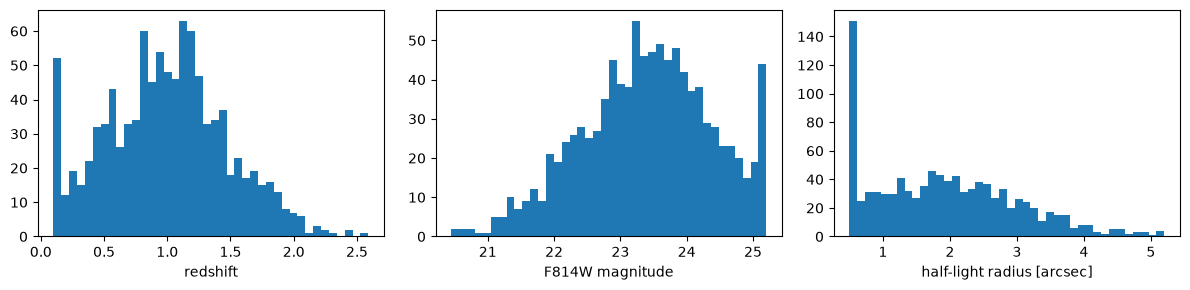

In [98]:
N = 1000
rng = np.random.default_rng(42)

z   = np.clip(rng.normal(1.0, 0.5, N), 0.1, 3.0)     # redshift
mag = np.clip(rng.normal(23.5, 1.0, N), 20.0, 25.2)  # F814W magnitude
r50 = np.clip(rng.normal(1.8, 1.2, N), 0.5, 5.2)     # half-light radius [arcsec]

cat = Table({"zphot": z, "mag_auto": mag, "flux_radius": r50 / 0.03}, dtype=[np.float32] * 3)

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].hist(z, 40);   ax[0].set_xlabel("redshift")
ax[1].hist(mag, 40); ax[1].set_xlabel("F814W magnitude")
ax[2].hist(r50, 40); ax[2].set_xlabel("half-light radius [arcsec]")
plt.tight_layout()

## Generate galaxies and draw them on the SKA grid

In [99]:
PIXEL_SCALE = 0.143   # arcsec / pixel
STAMP = 128           # DeepShape2 stamp size

model = galsim_hub.GenerativeGalaxyModel("hub:Lanusse2020")
galaxies = model.sample(cat, rng=galsim.BaseDeviate(1234))   # seeded, so the same galaxies every run
images = np.stack([g.drawImage(nx=STAMP, ny=STAMP, scale=PIXEL_SCALE, use_true_center=False).array
                   for g in galaxies])
images.shape

INFO:tensorflow:Saver not created because there are no variables in the graph to restore


INFO:tensorflow:Saver not created because there are no variables in the graph to restore


(1000, 128, 128)

## PSF

In [97]:
%%script /Users/isaacrosenberg/opt/anaconda3/envs/deepshape/bin/python
# Runs in the `deepshape` env. Same calls as deepshape2_part1, section 6.
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import numpy as np
np.linalg.norm(np.ones(2))   # macOS: wake up numpy before torch (as in part 1)
import torch
import astropy.units as u
from astropy.coordinates import SkyCoord

sys.path.insert(0, "/Users/isaacrosenberg/mass_internship/DeepShape2")
import deepshape2.simulation.visibilities as visibilities_module
from deepshape2.simulation import create_visibility_template, make_dirty_image_and_psf

SCALE_RAD = 6.93e-7          # 0.143 arcsec pixels (SKA-MID training value)
FREQ = 1.4e9                 # Hz
BANDWIDTH = 0.3 * FREQ       # Hz
RA, DEC = 56.0, -30.0        # deg
STAMP = 128

visibilities_module.CELLSIZE = SCALE_RAD      # = use_ska_mid_pixels() in part 1
visibilities_module.SCALE_RADIANS = SCALE_RAD

vis = create_visibility_template(SkyCoord(RA * u.deg, DEC * u.deg), frequency=FREQ, channel_bandwidth=BANDWIDTH)
psf = make_dirty_image_and_psf(vis, NPIX=STAMP, do_dirty=False, do_wstacking=False, threads=8)

np.savez("psf_ska_mid.npz", psf=np.asarray(psf, dtype=np.float64))
print("PSF", psf.shape, "peak", psf.max(), "at", np.unravel_index(psf.argmax(), psf.shape))

warning visibility_weight_to_griddata gridding: skipped 33 visbility


PSF (128, 128) peak 1.0 at (64, 64)


## Convolve with the PSF

In [100]:
psf = np.load("psf_ska_mid.npz")["psf"]
e_psf, _ = shape_galsim(psf)
print(f"PSF ellipticity: e1 = {e_psf[0]:.3f}, e2 = {e_psf[1]:.3f}")

def convolve_psf(img):
    return irfft2(rfft2(img) * rfft2(ifftshift(psf)), s=img.shape)

convolved = np.stack([convolve_psf(im) for im in images])

PSF ellipticity: e1 = 0.146, e2 = -0.039


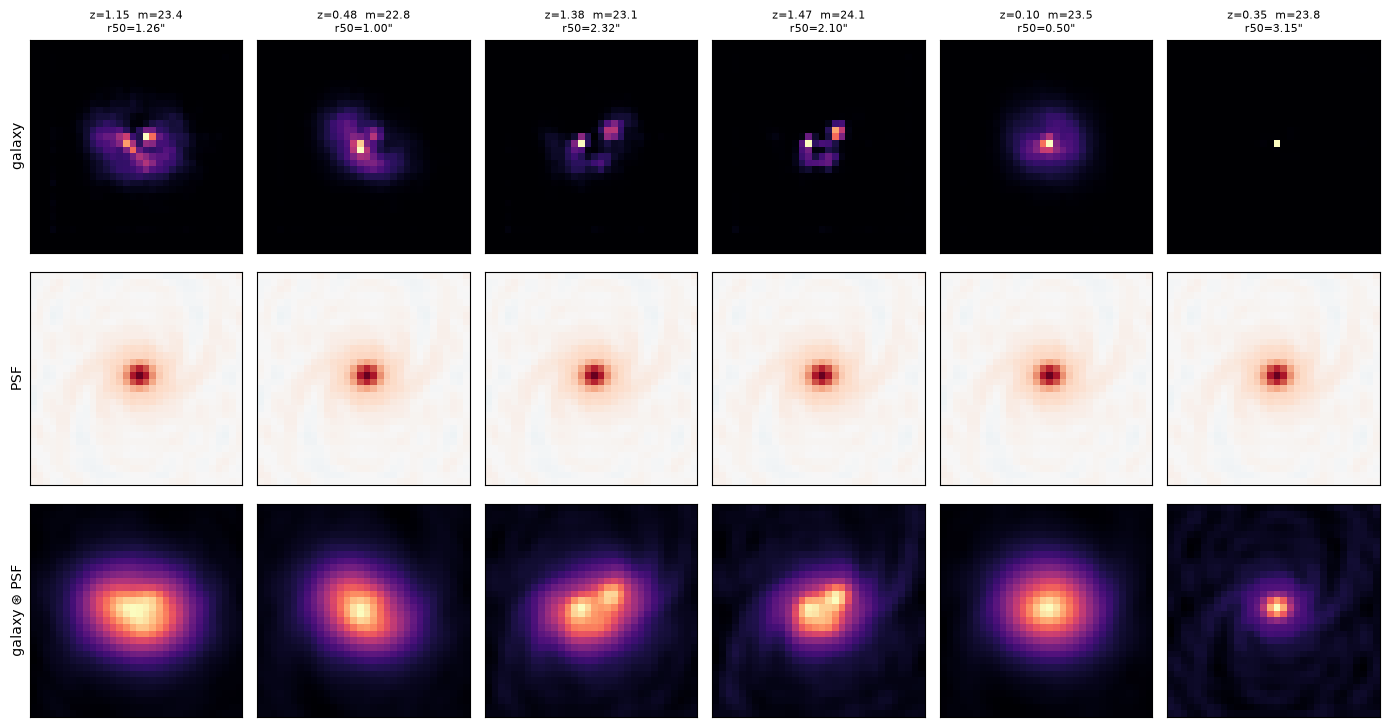

In [101]:
c, h = STAMP // 2, 16   # show the central 32 x 32 pixels (4.6")
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for j in range(6):
    axes[0, j].imshow(images[j][c - h:c + h, c - h:c + h], origin="lower", cmap="magma")
    axes[1, j].imshow(psf[c - h:c + h, c - h:c + h], origin="lower", cmap="RdBu_r", vmin=-1, vmax=1)
    axes[2, j].imshow(convolved[j][c - h:c + h, c - h:c + h], origin="lower", cmap="magma")
    axes[0, j].set_title(f"z={z[j]:.2f}  m={mag[j]:.1f}\nr50={r50[j]:.2f}\"", fontsize=8)
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
for a, label in zip(axes[:, 0], ["galaxy", "PSF", "galaxy ⊛ PSF"]):
    a.set_ylabel(label)
plt.tight_layout()

## Measure ellipticity before and after

In [102]:
e_before, ok_before = shape_galsim(images)
e_after,  ok_after  = shape_galsim(convolved)
ok = ok_before & ok_after
print(f"valid: before {ok_before.sum()}/{N}, after {ok_after.sum()}/{N}, both {ok.sum()}/{N}")

e1b, e2b = e_before[ok].T
e1a, e2a = e_after[ok].T

valid: before 680/1000, after 1000/1000, both 680/1000


### Ellipticity before vs after the PSF

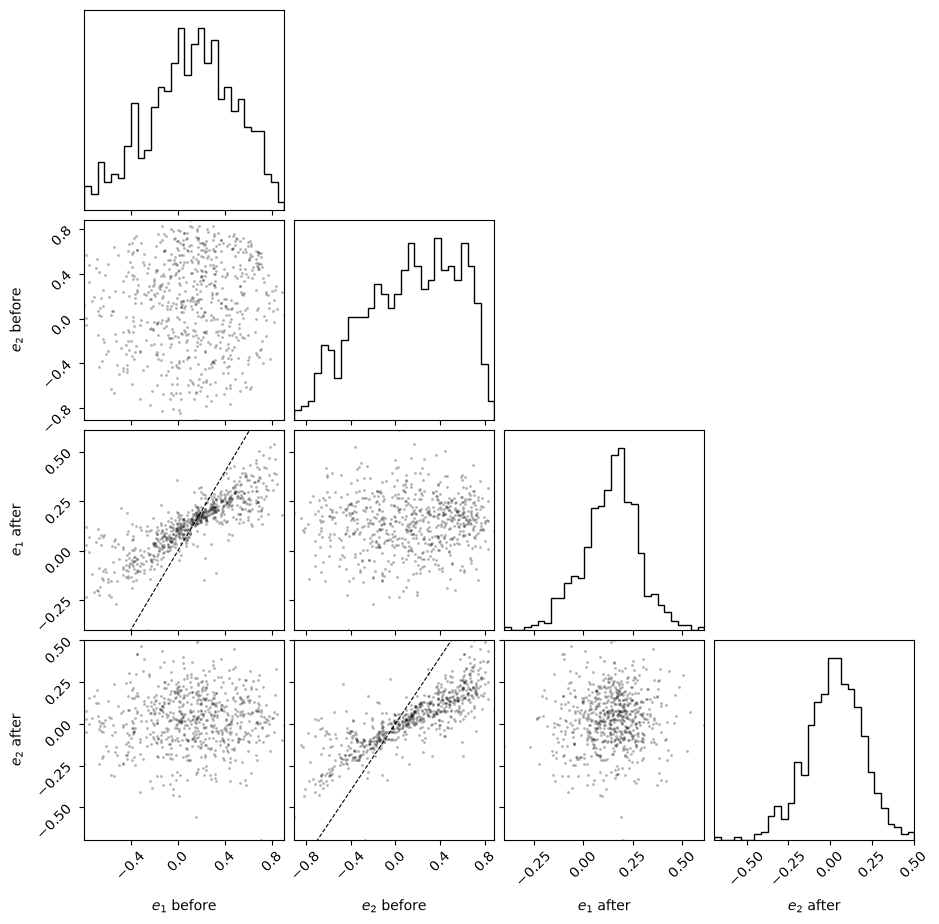

In [103]:
fig = corner.corner(np.column_stack([e1b, e2b, e1a, e2a]),
                    labels=[r"$e_1$ before", r"$e_2$ before", r"$e_1$ after", r"$e_2$ after"],
                    bins=30, plot_density=False, plot_contours=False, data_kwargs={"alpha": 0.3, "ms": 2})
# 1:1 lines on the before-vs-after panels
ax = np.array(fig.axes).reshape(4, 4)
for a in (ax[2, 0], ax[3, 1]):
    a.plot([-1, 1], [-1, 1], "k--", lw=0.8)

### How the PSF changes the shape vs redshift, size and magnitude

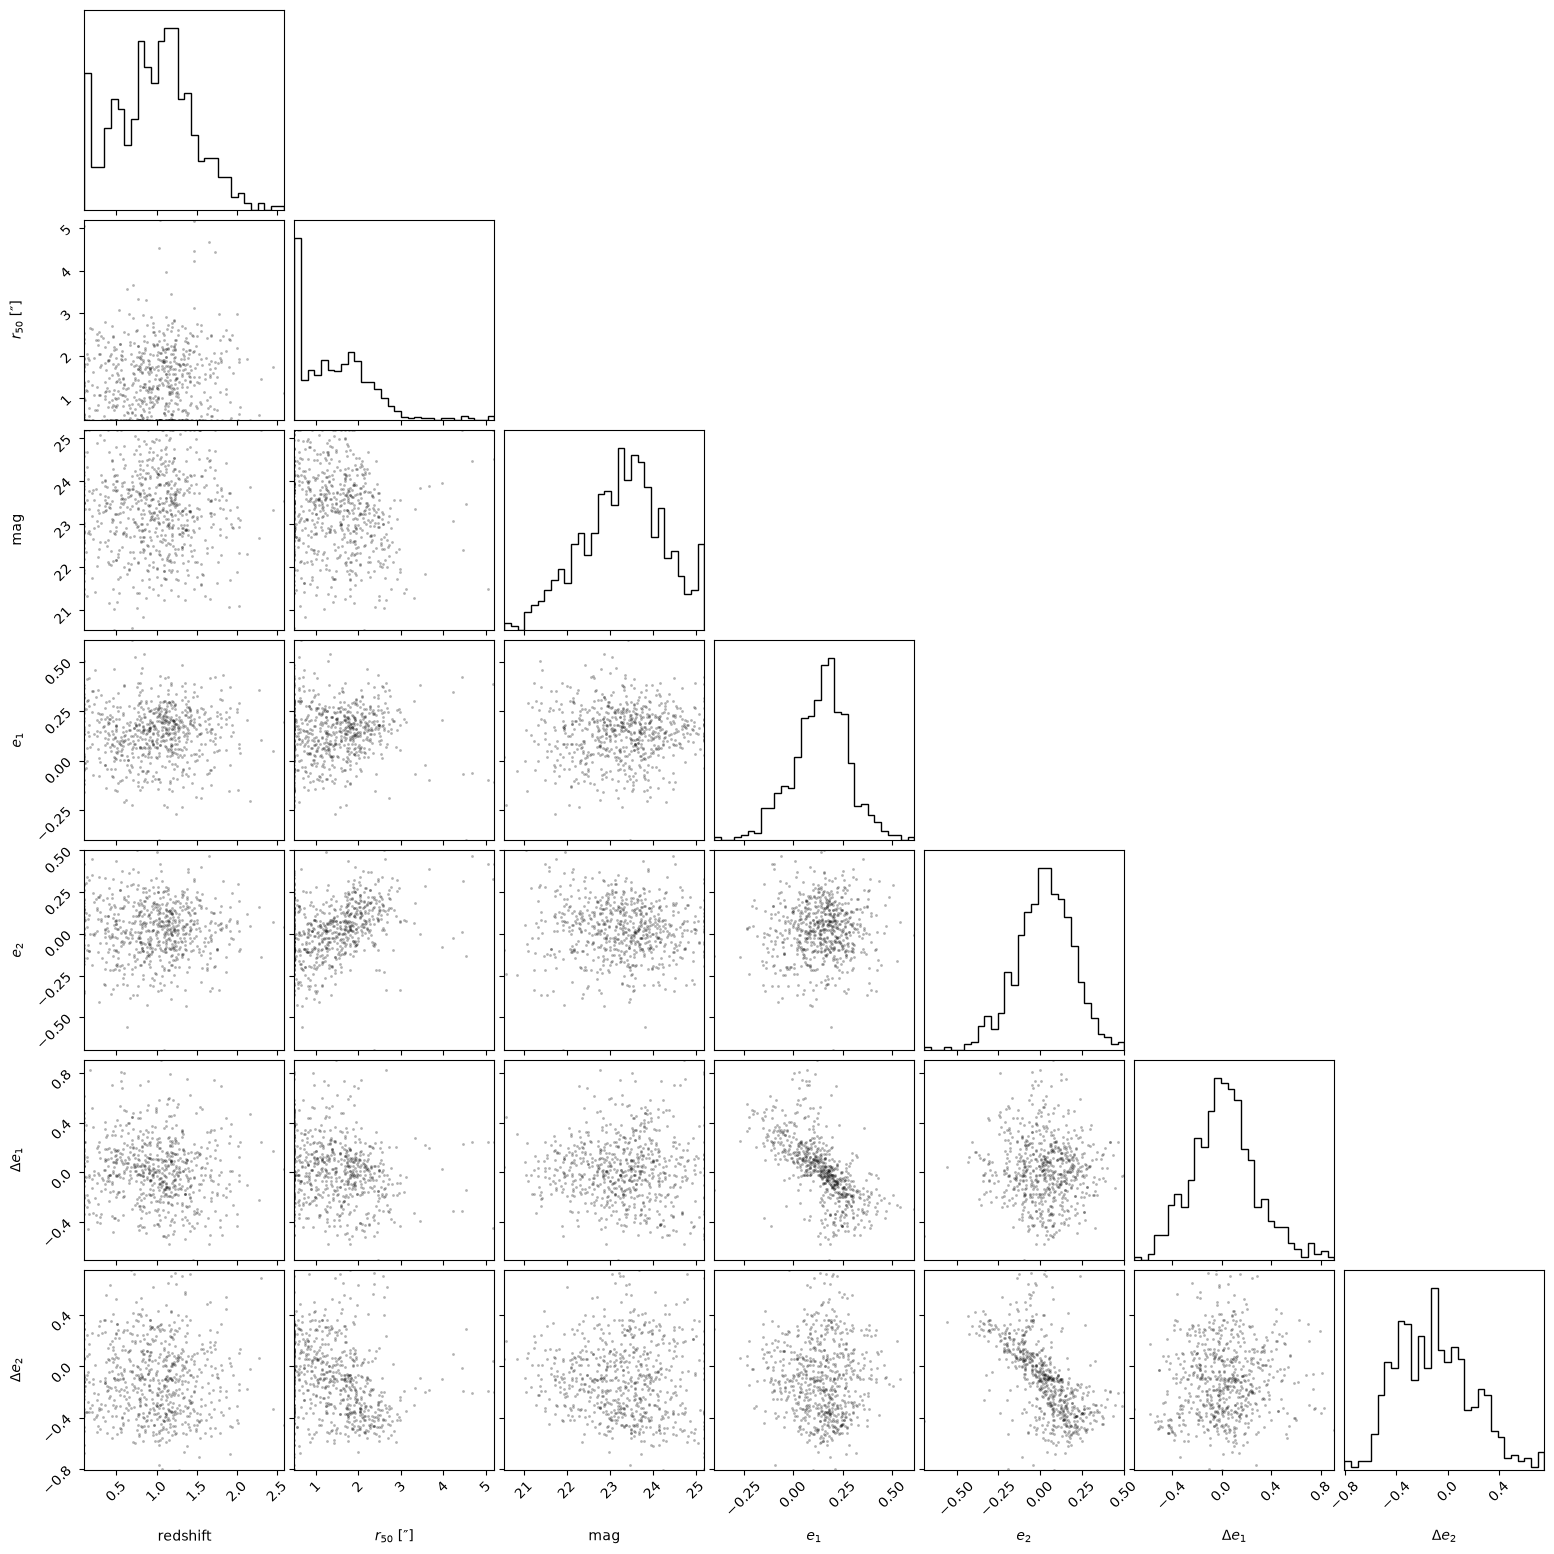

In [104]:
delta_e1 = (e1a - e1b)
delta_e2 = (e2a - e2b)

fig = corner.corner(np.column_stack([z[ok], r50[ok], mag[ok], e1a, e2a, delta_e1, delta_e2]),
                    labels=["redshift", r"$r_{50}$ [″]", "mag", r"$e_1$", r"$e_2$", r"$\Delta e_1$", r"$\Delta e_2$"],
                    bins=30, plot_density=False, plot_contours=False, data_kwargs={"alpha": 0.3, "ms": 2})